**ANN**

Task 1 - Sentinel 2 data to classify a patch as urban or forested area.

Explain how can you pose the given task into the form of a function?

**The classification task can be formulated as a mathematical mapping function f: R^{120000} -> {0, 1}, where each flattened 200x200x3 RGB image patch is represented as a 120,000-dimensional input vector x. The ANN approximates this function y = f(x;theta) by tuning its internal weights theta to output a probability score that classifies the patch as either forest 0 or urban 1.**

Training data

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split

np.random.seed(42)
tf.random.set_seed(42)

def extract_patches(image_path, patch_size=200):
    img = np.array(Image.open(image_path))[:, :, :3] / 255.0
    h, w, c = img.shape
    patches = []
    for y in range(0, h - patch_size + 1, patch_size):
        for x in range(0, w - patch_size + 1, patch_size):
            patch = img[y:y + patch_size, x:x + patch_size, :]
            patches.append(patch)
    return np.array(patches)

forest_patches = extract_patches('D:/agh/Machine-Learing/2026-08-25-00_00_2026-08-25-23_59_Sentinel-2_L2A_True_color.tiff', patch_size=200)
urban_patches = extract_patches('D:/agh/Machine-Learing/2026-10-08-00_00_2026-10-08-23_59_Sentinel-2_L2A_True_color.tiff', patch_size=200)

X = np.vstack([forest_patches, urban_patches])
y = np.array([0] * len(forest_patches) + [1] * len(urban_patches))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Total patches: {len(X)} | Train: {len(X_train)} | Test: {len(X_test)}")

Total patches: 144 | Train: 108 | Test: 36


What is the baritone ANN architecture you will need for this problem? 

**The baritone ANN architecture consists of an input Flatten layer that converts the 200x200x3 image patch into a 120,000-element vector, followed by a single hidden Dense layer with ReLU activation, and a single-neuron Dense output layer with a sigmoid activation function for binary classification.**

ANN Architecture & Execution

d:\conda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:36: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Baseline ANN - Test Loss: 0.2897 | Test Accuracy: 100.00%


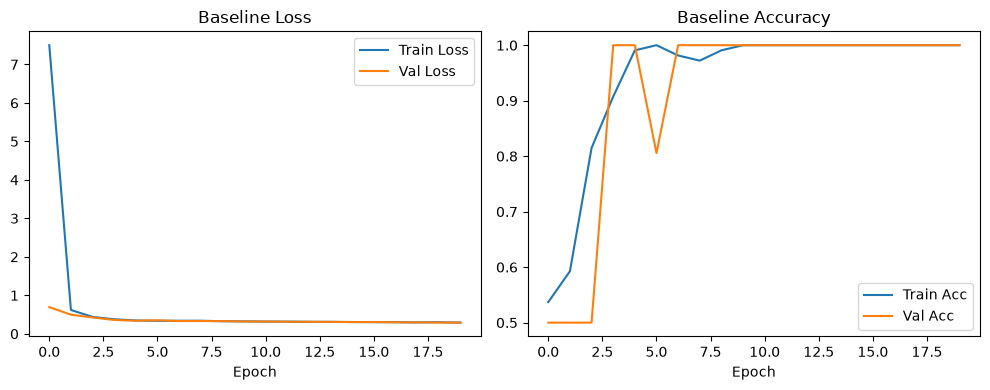

In [8]:
def build_baseline_ann():
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(200, 200, 3)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_ann()
history_base = baseline_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=8,
    validation_data=(X_test, y_test),
    verbose=0
)

base_loss, base_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
print(f"Baseline ANN - Test Loss: {base_loss:.4f} | Test Accuracy: {base_acc * 100:.2f}%")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_base.history['loss'], label='Train Loss')
plt.plot(history_base.history['val_loss'], label='Val Loss')
plt.title('Baseline Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_base.history['accuracy'], label='Train Acc')
plt.plot(history_base.history['val_accuracy'], label='Val Acc')
plt.title('Baseline Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

Running 5 Architectural & Hyperparameter Permutations

Configuration                                    | Test Loss  | Test Acc  
--------------------------------------------------------------------------
1. Baseline (64, ReLU, Adam 1e-3)                | 0.0033     |   100.00%
2. Wider Layer (256, ReLU, Adam 1e-3)            | 0.0040     |   100.00%
3. Deeper Network (128 -> 64, ReLU, Adam 1e-3)   | 0.0000     |   100.00%
4. Tanh Activation (128 -> 64, Tanh, Adam 1e-3)  | 0.0487     |   100.00%
5. SGD Optimizer (128 -> 64, ReLU, SGD 1e-2)     | 0.2039     |   100.00%


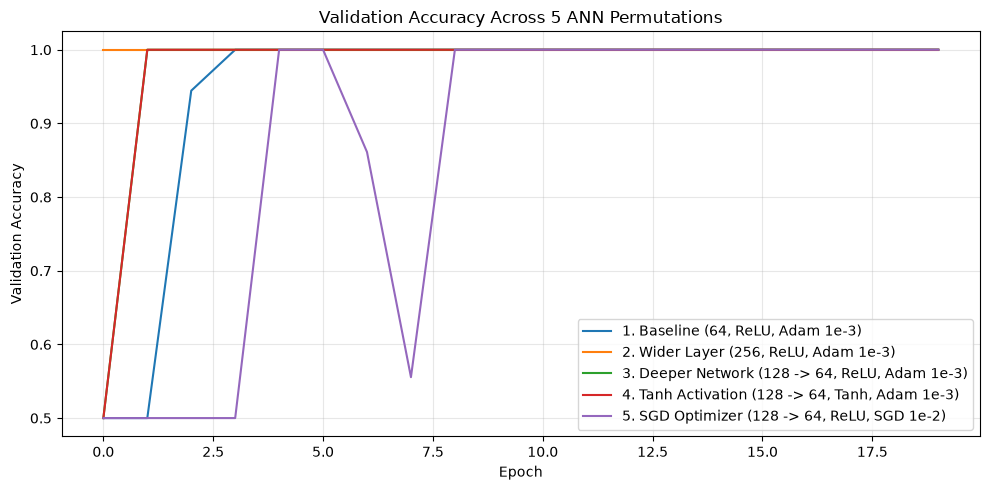

In [9]:
def create_permutation(config):
    layers = [tf.keras.layers.Flatten(input_shape=(200, 200, 3))]
    for units in config['layers']:
        layers.append(tf.keras.layers.Dense(units, activation=config['activation']))
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=config['optimizer'],
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

permutations = [
    {
        'name': '1. Baseline (64, ReLU, Adam 1e-3)',
        'layers': [64],
        'activation': 'relu',
        'optimizer': tf.keras.optimizers.Adam(learning_rate=0.001)
    },
    {
        'name': '2. Wider Layer (256, ReLU, Adam 1e-3)',
        'layers': [256],
        'activation': 'relu',
        'optimizer': tf.keras.optimizers.Adam(learning_rate=0.001)
    },
    {
        'name': '3. Deeper Network (128 -> 64, ReLU, Adam 1e-3)',
        'layers': [128, 64],
        'activation': 'relu',
        'optimizer': tf.keras.optimizers.Adam(learning_rate=0.001)
    },
    {
        'name': '4. Tanh Activation (128 -> 64, Tanh, Adam 1e-3)',
        'layers': [128, 64],
        'activation': 'tanh',
        'optimizer': tf.keras.optimizers.Adam(learning_rate=0.001)
    },
    {
        'name': '5. SGD Optimizer (128 -> 64, ReLU, SGD 1e-2)',
        'layers': [128, 64],
        'activation': 'relu',
        'optimizer': tf.keras.optimizers.SGD(learning_rate=0.01)
    }
]

results = []

for cfg in permutations:
    model = create_permutation(cfg)
    hist = model.fit(
        X_train, y_train,
        epochs=20,
        batch_size=8,
        validation_data=(X_test, y_test),
        verbose=0
    )
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results.append((cfg['name'], loss, acc, hist))

print(f"{'Configuration':<48} | {'Test Loss':<10} | {'Test Acc':<10}")
print("-" * 74)
for name, loss, acc, _ in results:
    print(f"{name:<48} | {loss:<10.4f} | {acc * 100:>8.2f}%")

plt.figure(figsize=(10, 5))
for name, _, _, hist in results:
    plt.plot(hist.history['val_accuracy'], label=name)
plt.title('Validation Accuracy Across 5 ANN Permutations')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Findings**

Across all five tested ANN permutations, the models rapidly converged to 100% classification accuracy, showing that the color distributions of forest and urban satellite patches are easily separable. While configurations using the Adam optimizer converged faster and achieved lower validation loss than SGD, adding more hidden layers or increasing the number of neurons provided no meaningful accuracy gain and only increased computational overhead. Consequently, a simple parametric Bayesian classifier is preferable for this task, as it achieves equivalent results almost instantaneously without requiring extensive training data or millions of learnable parameters.